In [70]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,ConfusionMatrixDisplay, confusion_matrix)


In [11]:
data=load_breast_cancer()
x=data.data
y=data.target

print("feature shape: ",x.shape)
print("traget shape: ",y.shape)
print("target names: ",data.target_names)

feature shape:  (569, 30)
traget shape:  (569,)
target names:  ['malignant' 'benign']


In [12]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,stratify=y,random_state=123)
rf_model=RandomForestClassifier(n_estimators=100,random_state=123)
rf_model.fit(x_train,y_train)
y_pred=rf_model.predict(x_test)
accuracy=accuracy_score(y_test,y_pred)
print(accuracy)


0.9649122807017544


In [16]:
print(classification_report(y_test,y_pred,target_names=data.target_names))

              precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        42
      benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



[[40  2]
 [ 2 70]]


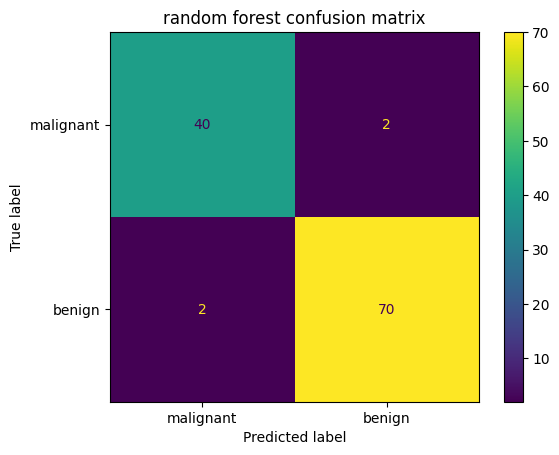

In [22]:
cm=confusion_matrix(y_test,y_pred)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=data.target_names)
disp.plot()
plt.title("random forest confusion matrix")
print(cm)

In [28]:
feature_importance=rf_model.feature_importances_
importance_df=pd.DataFrame({
    "Features":data.feature_names,
    "Importance":feature_importance
})
importance_df=importance_df.sort_values(by="Importance",ascending=False)
importance_df.head(10)


,Features,Importance
27,worst concave points,0.141762
22,worst perimeter,0.131715
23,worst area,0.121612
7,mean concave points,0.114481
20,worst radius,0.100036
6,mean concavity,0.047190
2,mean perimeter,0.045948
13,area error,0.045319
0,mean radius,0.034782
3,mean area,0.034160


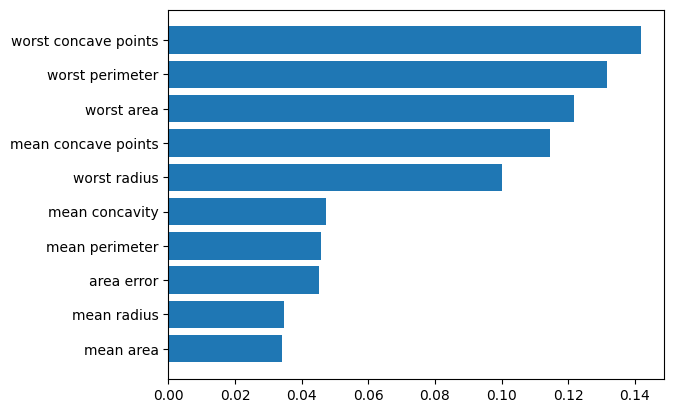

In [ ]:
plt.barh(importance_df.head(10)['Features'],importance_df.head(10)['Importance'])
plt.gca().invert_yaxis()
# plt.show()

In [38]:
rf_oob=RandomForestClassifier(
    n_estimators=100,
    bootstrap=True,
    oob_score=True,
    random_state=123
)
rf_oob.fit(x_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,True


In [39]:
y_pred2=rf_oob.predict(x_test)


In [42]:
# print(classification_report(y_test,y_pred))
print("oob score",rf_oob.oob_score_)

oob score 0.9582417582417583


In [43]:
oob_predictions=rf_oob.oob_decision_function_
print(oob_predictions[:5])

[[0.         1.        ]
 [0.03225806 0.96774194]
 [0.64102564 0.35897436]
 [0.39473684 0.60526316]
 [0.         1.        ]]


In [45]:
param_grid={
    "n_estimators":[100,200,300],
    "max_depth":[None,3,5,7,9,11],
    "min_samples_split":[2,5,10],
    "min_samples_leaf":[1,2,4],
    "max_features":["sqrt","log2"]
}

In [80]:
rf_grid_search=GridSearchCV(
    estimator=RandomForestClassifier(random_state=123,bootstrap=True),
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    return_train_score=True
    )

In [81]:
rf_grid_search.fit(x_train,y_train)

,estimator,RandomForestC...dom_state=123)
,param_grid,"{'max_depth': [None, 3, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,n_estimators,200


In [82]:
print(rf_grid_search.best_params_)

{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}


In [83]:
print(rf_grid_search.best_score_)

0.9597103485818748


In [84]:
print(rf_grid_search.best_estimator_)

RandomForestClassifier(min_samples_split=5, n_estimators=200, random_state=123)


In [57]:
rf_results=pd.DataFrame(rf_grid_search.cv_results_)
rf_results=rf_results.sort_values(by='rank_test_score')
rf_results[["params",

        "mean_train_score",

        "mean_test_score",

        "std_test_score",

        "rank_test_score"]].head(10)

,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
221,"{'max_depth': 9, 'max_features': 'sqrt', 'min_...",0.995604,0.962637,0.020382,1
167,"{'max_depth': 7, 'max_features': 'sqrt', 'min_...",0.995604,0.962637,0.020382,1
4,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.996703,0.962637,0.020382,1
5,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.995604,0.962637,0.020382,1
220,"{'max_depth': 9, 'max_features': 'sqrt', 'min_...",0.996703,0.962637,0.020382,1
164,"{'max_depth': 7, 'max_features': 'sqrt', 'min_...",0.998901,0.962637,0.020382,1
163,"{'max_depth': 7, 'max_features': 'sqrt', 'min_...",0.999451,0.962637,0.020382,1
275,"{'max_depth': 11, 'max_features': 'sqrt', 'min...",0.995604,0.962637,0.020382,1
274,"{'max_depth': 11, 'max_features': 'sqrt', 'min...",0.996703,0.962637,0.020382,1
162,"{'max_depth': 7, 'max_features': 'sqrt', 'min_...",0.998901,0.960440,0.023671,10


In [85]:
y_pred_gs=rf_grid_search.predict(x_test)
print("grid search accuracy",accuracy_score(y_test,y_pred_gs))
print(classification_report(y_test,y_pred_gs,target_names=data.target_names))

grid search accuracy 0.9649122807017544
              precision    recall  f1-score   support

   malignant       0.93      0.98      0.95        42
      benign       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



Text(0.5, 1.0, 'confusion matrix')

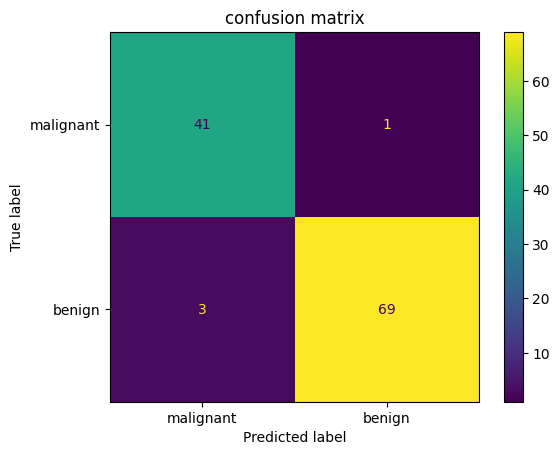

In [86]:
cm2=confusion_matrix(y_test,y_pred_gs)
disp2=ConfusionMatrixDisplay(confusion_matrix=cm2,display_labels=data.target_names)
disp2.plot()
plt.title("confusion matrix")

In [72]:
# creating decision tree for comparison

model_dt=DecisionTreeClassifier(max_depth=10,random_state=123)
model_dt.fit(x_train,y_train)
y_pred_dt=model_dt.predict(x_test)
print("decision tree accuracy: ",accuracy_score(y_test,y_pred_dt))

decision tree accuracy:  0.9649122807017544


In [79]:
cm_dt=confusion_matrix(y_test,y_pred_dt)
cm_dt

array([[41,  1],
       [ 3, 69]])

In [77]:
comparison=pd.DataFrame({
    "Models":[
        "Baseline Decision tree",
        "Random Forest classifier",
        "Tuned Random Forest Classifier"

    ],
    "accuracy":[
        accuracy_score(y_test,y_pred_dt),
        accuracy_score(y_test,y_pred),
        accuracy_score(y_test,y_pred_gs)
        
    ]
})

In [78]:
comparison

,Models,accuracy
0,Baseline Decision tree,0.964912
1,Random Forest classifier,0.964912
2,Tuned Random Forest Classifier,0.964912
